# 08 · Model comparison and feature analysis

Open this notebook from the Member 4 folder and choose **Run All Cells**. The input check lists each available partition and identifies any missing files. Once all three are present, the notebook fits the three models with each feature group and saves the measurements and plots in `results/`.

The default run uses reproducible stratified samples of up to 200,000 rows per partition. All nine fits share the same rows. Setting `SAMPLE_LIMIT = None` uses every event and requires more memory and time.

In [1]:
from pathlib import Path
import time
import pyarrow.parquet as pq
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve, auc)

DATA_DIR = Path('../data')
OUTPUT_DIR = Path('../reports/model_comparison/results')
RANDOM_STATE = 42
SAMPLE_LIMIT = 200_000  # set to None to use each full partition

## Historical project results

These scores come from earlier team runs. The split column identifies the evaluated partition. An empty metric means the source did not report it.

In [2]:
display(pd.read_csv('../reports/model_comparison/archived_model_metrics.csv'))
display(pd.read_csv('../reports/model_comparison/archived_feature_group_importance.csv'))
display(pd.read_csv('../reports/model_comparison/archived_feature_importance.csv').head(10))

,Model,Split,Rows,Accuracy,Precision,Recall,F1,ROC AUC,Average precision,Trapezoidal PR-AUC,Source
0,Decision Tree,Validation,1608195.0,0.705917,0.724614,0.740543,0.732492,0.776693,NaN,NaN,Drive performance_metrics.csv
1,Logistic Regression,Validation,1608195.0,0.644917,0.644427,0.773945,0.703272,0.683953,0.694720,NaN,"Drive validation_model_comparison.csv, baseline"
2,Random Forest,Validation,1608195.0,NaN,NaN,NaN,NaN,0.811383,NaN,NaN,"Drive validation_tuning.csv, selected candidate"
3,Logistic Regression,Test,1608196.0,0.645587,0.645018,0.774238,0.703745,0.684784,0.695657,NaN,"Drive test_metrics.csv, baseline"
4,Random Forest,Test,1608196.0,0.732686,0.741243,0.780962,0.760584,0.811599,NaN,0.833651,Drive test_metrics.csv and run_metadata.json
5,Decision Tree,Unspecified in plot,NaN,NaN,NaN,NaN,NaN,NaN,0.796800,NaN,"Drive precision_recall_curve.png, legend at 4 ..."


,Group,Decision Tree,Random Forest
0,High-level,0.835706,0.700153
1,Low-level,0.164294,0.299847


,Feature,Decision Tree,Random Forest,Group,Decision Tree rank,Random Forest rank
0,m_bb,0.388489,0.257704,High-level,1,1
1,m_wwbb,0.157262,0.129221,High-level,2,2
2,m_wbb,0.105471,0.106903,High-level,3,3
3,jet1_pT,0.092476,0.074845,Low-level,4,6
4,m_jlv,0.082946,0.075113,High-level,5,5
5,m_jjj,0.074013,0.087336,High-level,6,4
6,lepton_pT,0.030290,0.042784,Low-level,7,7
7,m_jj,0.022908,0.031770,High-level,8,10
8,missing_energy_magnitude,0.021561,0.037154,Low-level,9,8
9,jet2_pT,0.011476,0.033755,Low-level,10,9


![Archived results](../reports/model_comparison/figures/archived_performance.png)

![Archived feature importance](../reports/model_comparison/figures/archived_feature_importance.png)

## Check the local parquet files

In [3]:
LOW_LEVEL = ['lepton_pT', 'lepton_eta', 'lepton_phi', 'missing_energy_magnitude', 'missing_energy_phi']
for jet in range(1, 5):
    LOW_LEVEL.extend(f'jet{jet}_{quantity}' for quantity in ('pT', 'eta', 'phi', 'b_tag'))
HIGH_LEVEL = ['m_jj', 'm_jjj', 'm_lv', 'm_jlv', 'm_bb', 'm_wbb', 'm_wwbb']
FEATURES = LOW_LEVEL + HIGH_LEVEL
FEATURE_GROUPS = {'Low-Level (21)': LOW_LEVEL, 'High-Level (7)': HIGH_LEVEL, 'All Features (28)': FEATURES}

paths = {name: DATA_DIR / f'{name}.parquet' for name in ('train', 'validation', 'test')}
missing = []
for name, path in paths.items():
    if not path.is_file():
        missing.append(path)
        continue
    parquet = pq.ParquetFile(path)
    if sorted(parquet.schema_arrow.names) != sorted(['target', *FEATURES]):
        raise ValueError(f'{path}: expected target and the 28 named HIGGS features.')
    print(f'{name}: {parquet.metadata.num_rows:,} rows; feature names checked.')
    parquet.close()

ready = not missing
if missing:
    print('To run the experiments, add the following file(s) and run all cells again:')
    for path in missing:
        print(path.resolve())

train: 7,504,911 rows; feature names checked.
validation: 1,608,195 rows; feature names checked.
test: 1,608,196 rows; feature names checked.


In [4]:
def load_partition(path, limit, seed):
    # Only the labels need to fit in memory for the stratified draw.
    with pq.ParquetFile(path) as parquet:
        labels = parquet.read(columns=['target']).column('target').combine_chunks().to_numpy(zero_copy_only=False)
        if not np.array_equal(np.unique(labels), [0, 1]):
            raise ValueError(f'{path}: expected both binary target classes 0 and 1.')
        selected = None
        if limit is not None and limit < len(labels):
            if limit < 2:
                raise ValueError('SAMPLE_LIMIT must allow at least one event from each class.')
            rng = np.random.default_rng(seed)
            positive_rows = np.flatnonzero(labels == 1)
            negative_rows = np.flatnonzero(labels == 0)
            n_positive = int(np.clip(round(limit * len(positive_rows) / len(labels)),
                                     max(1, limit - len(negative_rows)), min(limit - 1, len(positive_rows))))
            selected = np.sort(np.concatenate([
                rng.choice(positive_rows, n_positive, replace=False),
                rng.choice(negative_rows, limit - n_positive, replace=False),
            ]))
        pieces = []
        offset = 0
        for batch in parquet.iter_batches(batch_size=65_536, columns=FEATURES):
            stop = offset + batch.num_rows
            if selected is not None:
                left, right = np.searchsorted(selected, [offset, stop])
                batch = batch.take(selected[left:right] - offset)
            if batch.num_rows:
                frame = batch.to_pandas()
                if not np.isfinite(frame.to_numpy()).all():
                    raise ValueError(f'{path}: non-finite values in selected features.')
                pieces.append(frame)
            offset = stop
    X = pd.concat(pieces, ignore_index=True)
    y = pd.Series(labels if selected is None else labels[selected], name='target')
    print(f'{path.stem}: using {len(y):,} rows, {y.mean():.2%} signal')
    return X, y

if ready:
    X_train, y_train = load_partition(paths['train'], SAMPLE_LIMIT, RANDOM_STATE)
    X_val, y_val = load_partition(paths['validation'], SAMPLE_LIMIT, RANDOM_STATE + 1)
    X_test, y_test = load_partition(paths['test'], SAMPLE_LIMIT, RANDOM_STATE + 2)
    OUTPUT_DIR.mkdir(exist_ok=True)

train: using 200,000 rows, 54.37% signal


validation: using 200,000 rows, 54.37% signal


test: using 200,000 rows, 54.37% signal


## Consistent model comparison

All three models use the same sampled training rows and are scored against the same validation and test rows. The test partition should be used once for final reporting; do not adjust model settings after reviewing test scores. Precision, recall, and F1 use signal (label 1) as the positive class. The run reports average precision and trapezoidal PR-AUC separately. The models share fixed settings across the three feature groups.


In [5]:
MODELS = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, solver='lbfgs', random_state=RANDOM_STATE)),
    'Decision Tree': DecisionTreeClassifier(criterion='gini', max_depth=10, min_samples_split=50, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=16,
                                            max_features='sqrt', n_jobs=2, random_state=RANDOM_STATE),
}

def score_model(model, X, y):
    pred = model.predict(X)
    score = model.predict_proba(X)[:, 1]
    curve_precision, curve_recall, _ = precision_recall_curve(y, score)
    return {
        'accuracy': accuracy_score(y, pred),
        'precision_positive_class': precision_score(y, pred, pos_label=1, zero_division=0),
        'recall_positive_class': recall_score(y, pred, pos_label=1, zero_division=0),
        'f1_positive_class': f1_score(y, pred, pos_label=1, zero_division=0),
        'roc_auc': roc_auc_score(y, score),
        'average_precision': average_precision_score(y, score),
        'pr_auc_trapezoidal': auc(curve_recall, curve_precision),
    }

if ready:
    records = []
    all_feature_models = {}
    for group_name, columns in FEATURE_GROUPS.items():
        for model_name, estimator in MODELS.items():
            model = clone(estimator)
            start = time.perf_counter()
            model.fit(X_train[columns], y_train)
            fit_seconds = time.perf_counter() - start
            print(f'{group_name} | {model_name}: fit finished in {fit_seconds:.1f}s', flush=True)
            for split_name, X_split, y_split in [('validation', X_val, y_val), ('test', X_test, y_test)]:
                row = {'feature_group': group_name, 'model': model_name, 'split': split_name,
                       'fit_seconds': fit_seconds, 'train_rows_used': len(X_train), 'eval_rows_used': len(y_split)}
                row.update(score_model(model, X_split[columns], y_split))
                records.append(row)
            if group_name == 'All Features (28)':
                all_feature_models[model_name] = model

    results = pd.DataFrame(records)
    results.to_csv(OUTPUT_DIR / 'model_comparison_metrics.csv', index=False)
    display(results.query("split == 'test'").sort_values(['feature_group', 'model']))

Low-Level (21) | Logistic Regression: fit finished in 0.2s


Low-Level (21) | Decision Tree: fit finished in 3.6s


Low-Level (21) | Random Forest: fit finished in 15.8s


High-Level (7) | Logistic Regression: fit finished in 0.1s


High-Level (7) | Decision Tree: fit finished in 1.5s


High-Level (7) | Random Forest: fit finished in 10.1s


All Features (28) | Logistic Regression: fit finished in 0.2s


All Features (28) | Decision Tree: fit finished in 5.1s


All Features (28) | Random Forest: fit finished in 20.0s


,feature_group,model,split,fit_seconds,train_rows_used,eval_rows_used,accuracy,precision_positive_class,recall_positive_class,f1_positive_class,roc_auc,average_precision,pr_auc_trapezoidal
15,All Features (28),Decision Tree,test,5.074323,200000,200000,0.695635,0.713527,0.735477,0.724336,0.762121,0.778765,0.774194
13,All Features (28),Logistic Regression,test,0.242098,200000,200000,0.647030,0.646796,0.772814,0.704212,0.685509,0.695565,0.695559
17,All Features (28),Random Forest,test,19.987916,200000,200000,0.721430,0.730915,0.771756,0.750781,0.798309,0.822443,0.822441
9,High-Level (7),Decision Tree,test,1.525032,200000,200000,0.684815,0.696588,0.744627,0.719807,0.752670,0.773913,0.767179
7,High-Level (7),Logistic Regression,test,0.105172,200000,200000,0.631460,0.622077,0.820819,0.707761,0.647868,0.633542,0.633532
11,High-Level (7),Random Forest,test,10.113458,200000,200000,0.702855,0.715806,0.752058,0.733484,0.777839,0.805270,0.805269
3,Low-Level (21),Decision Tree,test,3.566891,200000,200000,0.614435,0.639846,0.665355,0.652351,0.652606,0.677552,0.678703
1,Low-Level (21),Logistic Regression,test,0.200613,200000,200000,0.570425,0.580390,0.757695,0.657295,0.595128,0.635870,0.635860
5,Low-Level (21),Random Forest,test,15.821524,200000,200000,0.639970,0.645658,0.748701,0.693372,0.693495,0.722962,0.722959


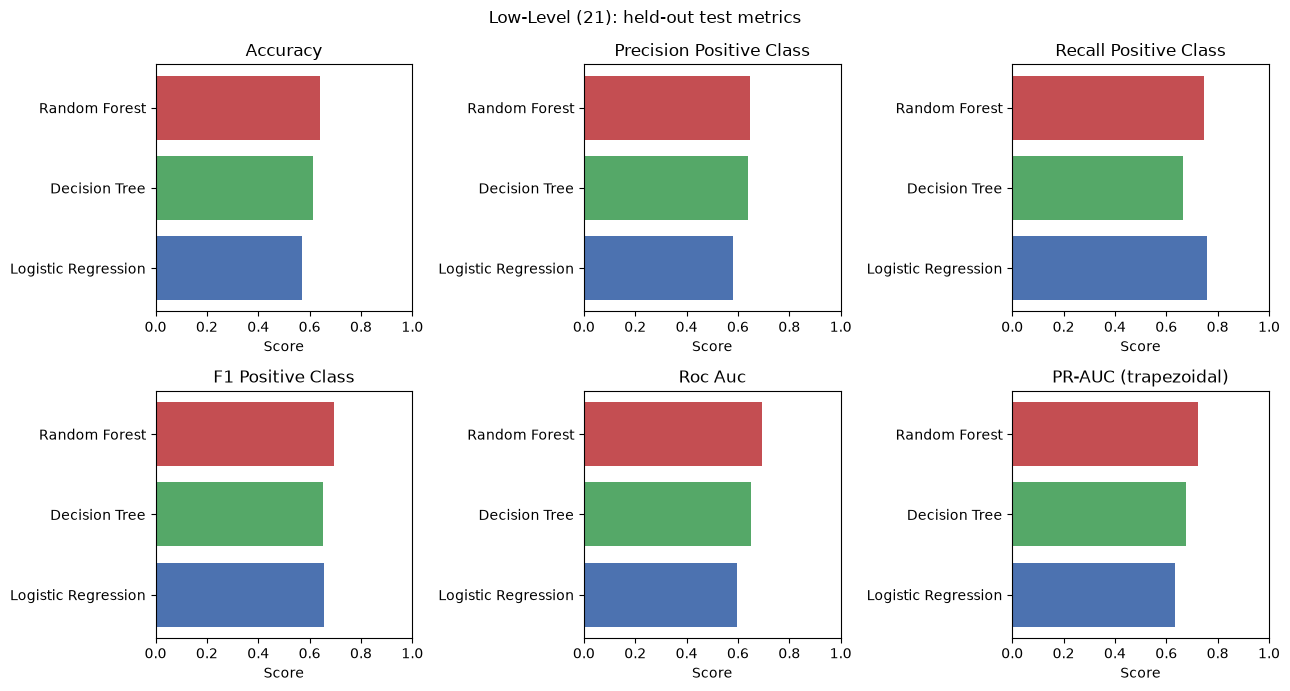

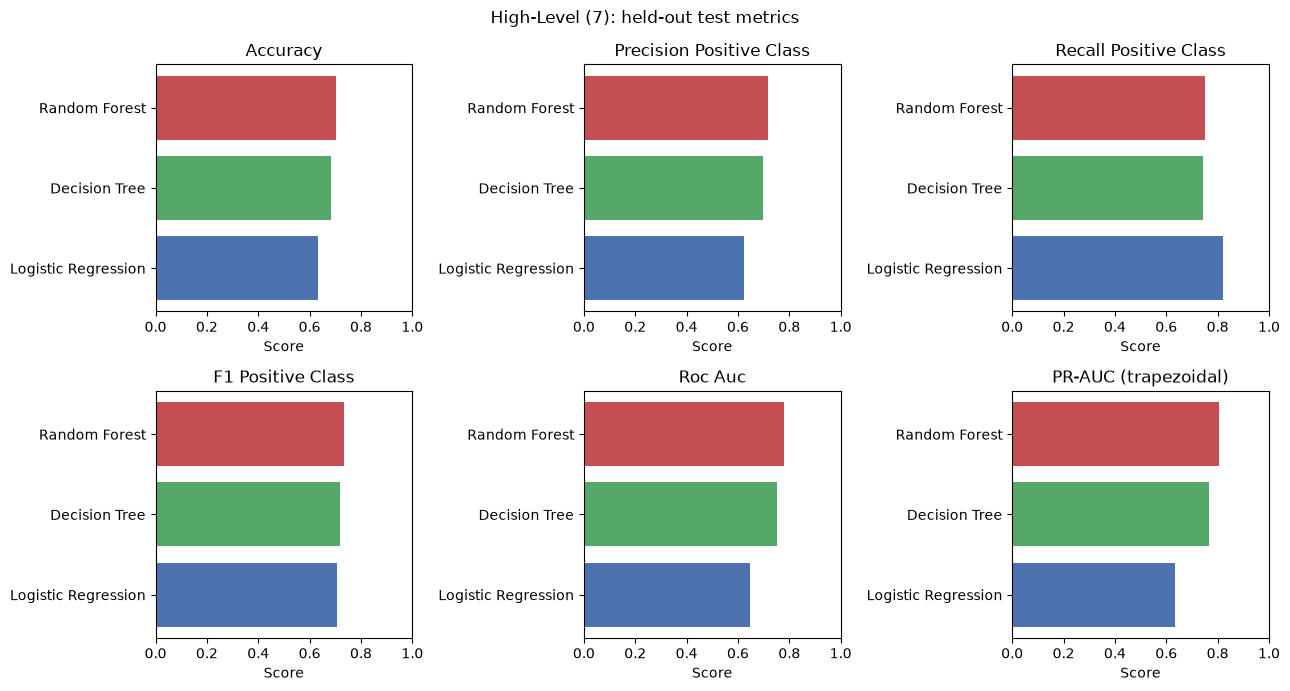

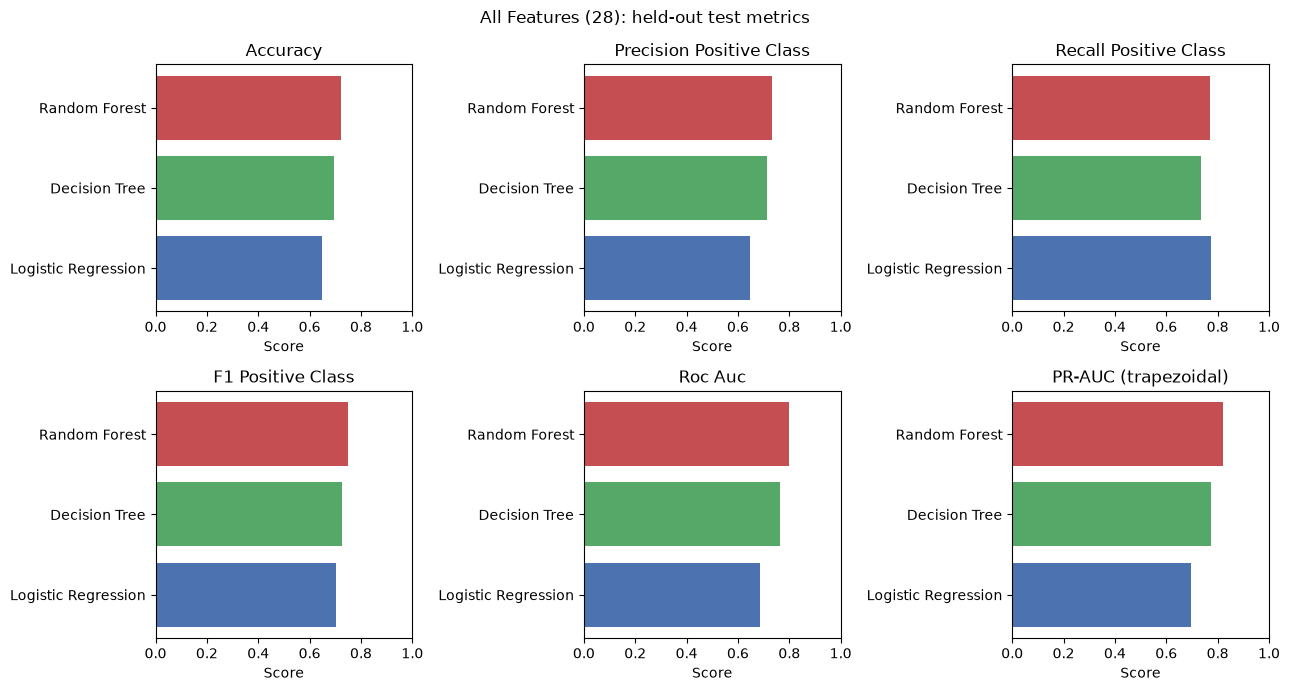

In [6]:
if ready:
    # Requested six-metric comparison plot, based on the common test partition.
    metric_cols = ['accuracy', 'precision_positive_class', 'recall_positive_class',
                   'f1_positive_class', 'roc_auc', 'pr_auc_trapezoidal']
    plot_data = results.query("split == 'test'").copy()
    for group_name, frame in plot_data.groupby('feature_group', sort=False):
        fig, axes = plt.subplots(2, 3, figsize=(13, 7))
        for ax, metric in zip(axes.flat, metric_cols):
            subset = frame.set_index('model').loc[list(MODELS)].reset_index()
            ax.barh(subset.model, subset[metric], color=['#4c72b0', '#55a868', '#c44e52'])
            ax.set_xlim(0, 1)
            ax.set_title('PR-AUC (trapezoidal)' if metric == 'pr_auc_trapezoidal' else metric.replace('_', ' ').title())
            ax.set_xlabel('Score')
        fig.suptitle(f'{group_name}: held-out test metrics')
        fig.tight_layout()
        fig.savefig(OUTPUT_DIR / f"metrics_{group_name.split()[0].lower()}.png", dpi=180, bbox_inches='tight')
        plt.show()

## Feature importance: Decision Tree vs Random Forest

The plots below use each model's impurity-based `feature_importances_`, normalized within that fitted model. These scores describe split contribution inside a model; they are not causal effects and can favor variables with many possible split points. Compare rankings and group sums as descriptive evidence.


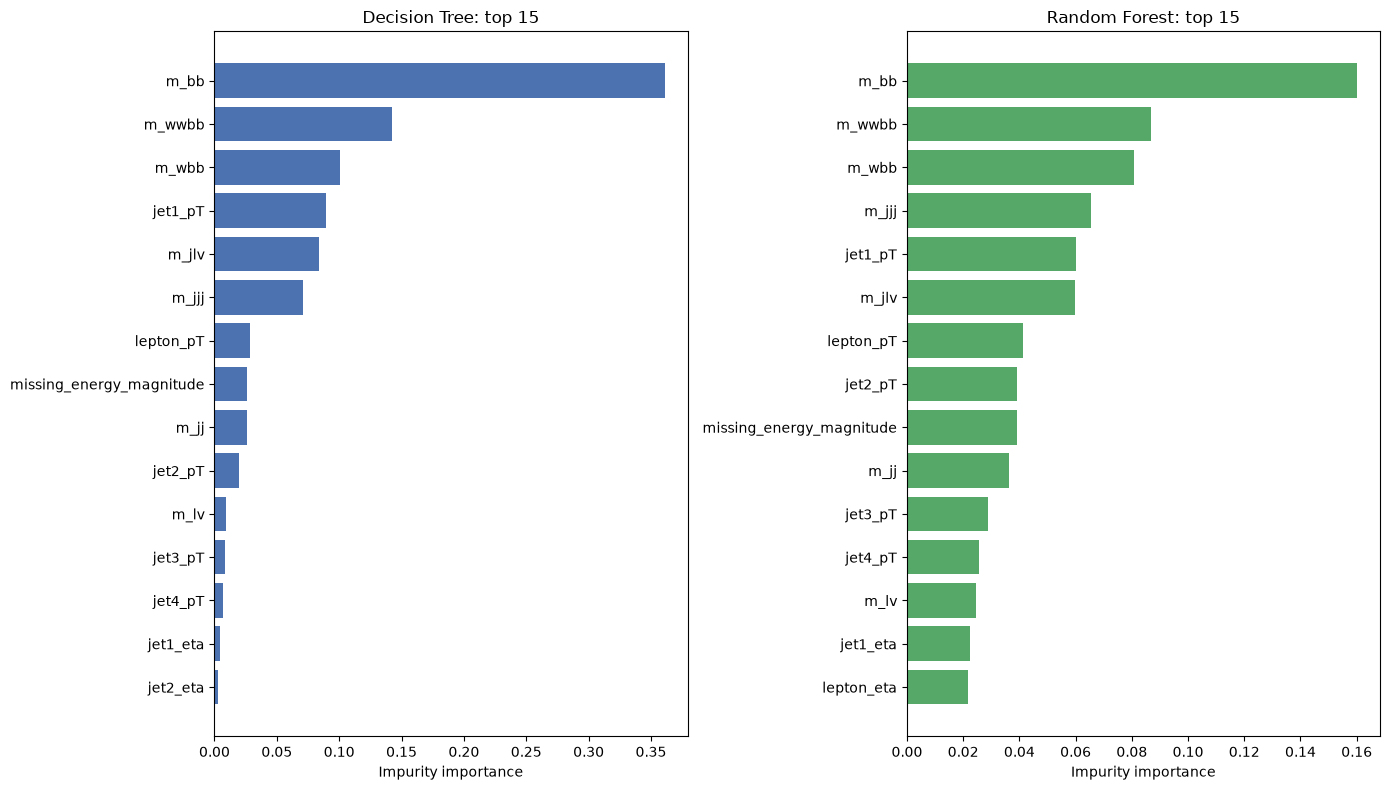

model,Decision Tree,Random Forest
feature,,
m_bb,0.361206,0.160270
m_wwbb,0.142364,0.086803
m_wbb,0.100580,0.080598
m_jjj,0.071031,0.065514
jet1_pT,0.089702,0.059989
m_jlv,0.083900,0.059844
lepton_pT,0.028201,0.041361
jet2_pT,0.019330,0.039216
missing_energy_magnitude,0.026105,0.038975


In [7]:
if ready:
    importance_frames = []
    for model_name in ('Decision Tree', 'Random Forest'):
        fitted = all_feature_models[model_name]
        core = fitted.steps[-1][1] if hasattr(fitted, 'steps') else fitted
        importance_frames.append(pd.DataFrame({'feature': FEATURES, 'importance': core.feature_importances_, 'model': model_name}))
    importance = pd.concat(importance_frames, ignore_index=True)
    importance.to_csv(OUTPUT_DIR / 'feature_importance_dt_rf.csv', index=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 8))
    for ax, model_name in zip(axes, ('Decision Tree', 'Random Forest')):
        top = importance.query('model == @model_name').nlargest(15, 'importance').sort_values('importance')
        ax.barh(top.feature, top.importance, color='#4c72b0' if model_name == 'Decision Tree' else '#55a868')
        ax.set_title(f'{model_name}: top 15')
        ax.set_xlabel('Impurity importance')
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / 'feature_importance_dt_rf.png', dpi=180, bbox_inches='tight')
    plt.show()
    display(importance.pivot(index='feature', columns='model', values='importance').sort_values('Random Forest', ascending=False).head(15))